In [1]:
import pandas as pd
from pathlib import Path

In [2]:
data_path = Path("../data/raw/train.csv")
df = pd.read_csv(data_path)

In [3]:
# Display shape (rows and columns) of the dataset
rows, cols = df.shape
print(f"Dataset contains {rows} rows and {cols} columns")

Dataset contains 3000888 rows and 6 columns


In [4]:
# Display column names, their count of non-null values and dtypes
print("Dataset have the following columns, count of non-null values and data types")
print()
df.info(show_counts=True)

Dataset have the following columns, count of non-null values and data types

<class 'pandas.DataFrame'>
RangeIndex: 3000888 entries, 0 to 3000887
Data columns (total 6 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   id           3000888 non-null  int64  
 1   date         3000888 non-null  str    
 2   store_nbr    3000888 non-null  int64  
 3   family       3000888 non-null  str    
 4   sales        3000888 non-null  float64
 5   onpromotion  3000888 non-null  int64  
dtypes: float64(1), int64(3), str(2)
memory usage: 137.4 MB


Worth noting that the `date` column was read as an type object (string) by pandas. Due to the nature of the project, I will convert said column to proper datetime object.

In [5]:
# Convert 'date' column to proper pandas datetime object using pd.to_datetime(), coercing errors
df["date"] = pd.to_datetime(df["date"], errors="coerce")

# Verify conversion and check for NaT values
print("Date dtype:", df["date"].dtype)
print("Invalid dates:", df["date"].isna().sum())

Date dtype: datetime64[us]
Invalid dates: 0


In [6]:
# Display first 5 rows of the dataset
df.head()

,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0
4,4,2013-01-01,1,BOOKS,0.0,0


In [7]:
# Display date range (min and max dates)
min_date, max_date = df["date"].min(), df["date"].max()
print(f"Date range: {min_date:%Y-%m-%d} to {max_date:%Y-%m-%d}")

# Display date difference in days
date_diff_days = (max_date - min_date).days + 1
print(f"Expected calendar days: {date_diff_days}")

# Display number of unique observed dates
unique_dates = df["date"].nunique()
print(f"Observed unique dates: {unique_dates}")

# Display number of days missing (vs expected for the date range)
n_missing_dates = date_diff_days - unique_dates
print(f"Dataset is missing {n_missing_dates} days from the calendar range")

Date range: 2013-01-01 to 2017-08-15
Expected calendar days: 1688
Observed unique dates: 1684
Dataset is missing 4 days from the calendar range


In [8]:
# Create a set of dates between min_date and max_date
date_range = set(pd.date_range(min_date, max_date))

# Compare the date_range set with a set of df["date"]
missing_dates = date_range.difference(set(df["date"]))

# Display the dates missing from 'date' column
print(sorted(missing_dates))

[Timestamp('2013-12-25 00:00:00'), Timestamp('2014-12-25 00:00:00'), Timestamp('2015-12-25 00:00:00'), Timestamp('2016-12-25 00:00:00')]


The dataset covers 1,688 calendar days but contains observations for only 1,684. All four missing dates correspond to December 25 (2013–2016), suggesting a systematic holiday-related reporting gap rather than randomly missing observations.

In [9]:
# Display number of missing values in the dataset
df.isna().sum()

id             0
date           0
store_nbr      0
family         0
sales          0
onpromotion    0
dtype: int64

There are no missing values in any of the columns of the dataset.

In [10]:
# Check for duplicated date + store_nbr + family combinations
df.duplicated(subset=["date", "store_nbr", "family"]).sum()

np.int64(0)

As expected, `(date, store_nbr, family)` contains no duplicates and is a unique composite key.

### Target Distribution (sales)

In [11]:
df["sales"].describe().round(2)

count    3000888.00
mean         357.78
std         1102.00
min            0.00
25%            0.00
50%           11.00
75%          195.85
max       124717.00
Name: sales, dtype: float64

- The target contains no negative values, as expected.
- Smallest (min) value is 0, which could be a perfectly legitimate observation rather than missing data
- Highest (max) value is a sale recorded at 124717.
- Mean sits at 357.78, and median (50%) is at 11.00. The mean is being distorted by extremely high values (outliers), while 75% of the values have a value under 195.85.

In [12]:
# Get count of rows where 'sales' = 0 and how much they represent of the whole dataset
count_of_zero_sales = df[df["sales"] == 0]["sales"].count()
print(count_of_zero_sales)
pct_of_zero_sales = count_of_zero_sales / df.shape[0] * 100
pct_of_zero_sales

939130


np.float64(31.29506999261552)

Out of the 3000888 rows in the dataset, 939130 show a 'sales' of 0 (approximately 31.3%).

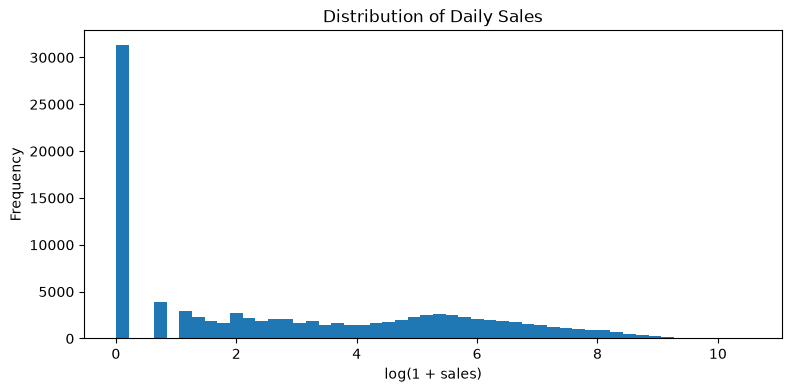

In [14]:
import numpy as np
import matplotlib.pyplot as plt

sample = df["sales"].sample(n=100_000, random_state=42)

plt.figure(figsize=(9, 4))
plt.hist(np.log1p(sample), bins=50)
plt.xlabel("log(1 + sales)")
plt.ylabel("Frequency")
plt.title("Distribution of Daily Sales")
plt.show()

The distribution of daily sales exhibits a substantial concentration at zero (31.3% of observations), alongside a broad distribution of positive sales values. Applying a log(1 + sales) transformation improves visibility of the positive-sales distribution but does not eliminate its irregular shape. This suggests considerable heterogeneity across stores and product families.

In [20]:
number_of_unique_stores = df["store_nbr"].nunique()
print(f"Number of unique stores: {number_of_unique_stores}")

Number of unique stores: 54


In [21]:
number_of_unique_families = df["family"].nunique()
print(f"Number of unique families: {number_of_unique_families}")

Number of unique families: 33


In [27]:
observed_combinations = (
    df[["store_nbr", "family"]]
    .drop_duplicates()
    .shape[0]
)

print(f"Observed store-family combinations: {observed_combinations}")

Observed store-family combinations: 1782


In [28]:
df.groupby(["store_nbr", "family"]).size()

store_nbr  family                    
1          AUTOMOTIVE                    1684
           BABY CARE                     1684
           BEAUTY                        1684
           BEVERAGES                     1684
           BOOKS                         1684
                                         ... 
54         POULTRY                       1684
           PREPARED FOODS                1684
           PRODUCE                       1684
           SCHOOL AND OFFICE SUPPLIES    1684
           SEAFOOD                       1684
Length: 1782, dtype: int64

In [29]:
series_counts = df.groupby(["store_nbr", "family"]).size()

print(series_counts.describe())
print(f"All series have equal length: {series_counts.nunique() == 1}")

count    1782.0
mean     1684.0
std         0.0
min      1684.0
25%      1684.0
50%      1684.0
75%      1684.0
max      1684.0
dtype: float64
All series have equal length: True


- There are 1,782 individual time series.
- Every series contains 1,684 daily observations.
- All series share the same dates, given the unique composite key and total number of observed dates.
- The only calendar gaps are the four missing Christmas Days.

In [31]:
sales_by_date = df.groupby("date", as_index=False).agg(
    total_sales=("sales", "sum")
)

In [32]:
import seaborn as sns

Text(0, 0.5, 'Sales ($)')

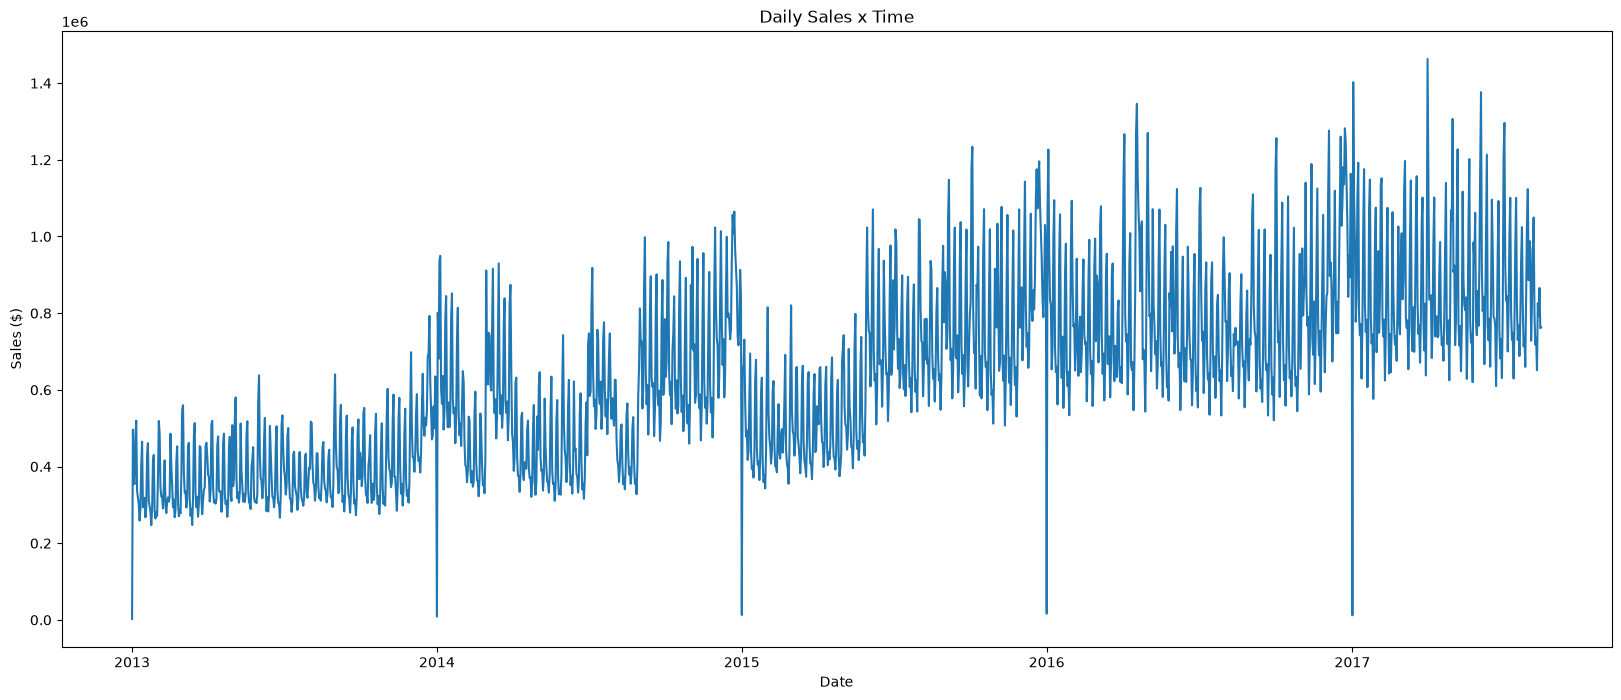

In [36]:
plt.figure(figsize=(20, 8))
sns.lineplot(
    data=sales_by_date,
    x="date",
    y="total_sales"
)
plt.title("Daily Sales x Time")
plt.xlabel("Date")
plt.ylabel("Sales ($)")

Aggregate daily sales exhibit a clear upward trend between 2013 and 2017, accompanied by recurring seasonal fluctuations. Repeated short-term oscillations suggest weekly seasonality, while larger peaks appear around certain periods of the year. Sales variability also increases over time, potentially indicating a relationship between seasonal amplitude and overall sales volume. Sharp year-end drops warrant further investigation.

In [44]:
sales_by_date["week_day_name"] = sales_by_date["date"].dt.day_name()

Text(0, 0.5, 'Sales ($)')

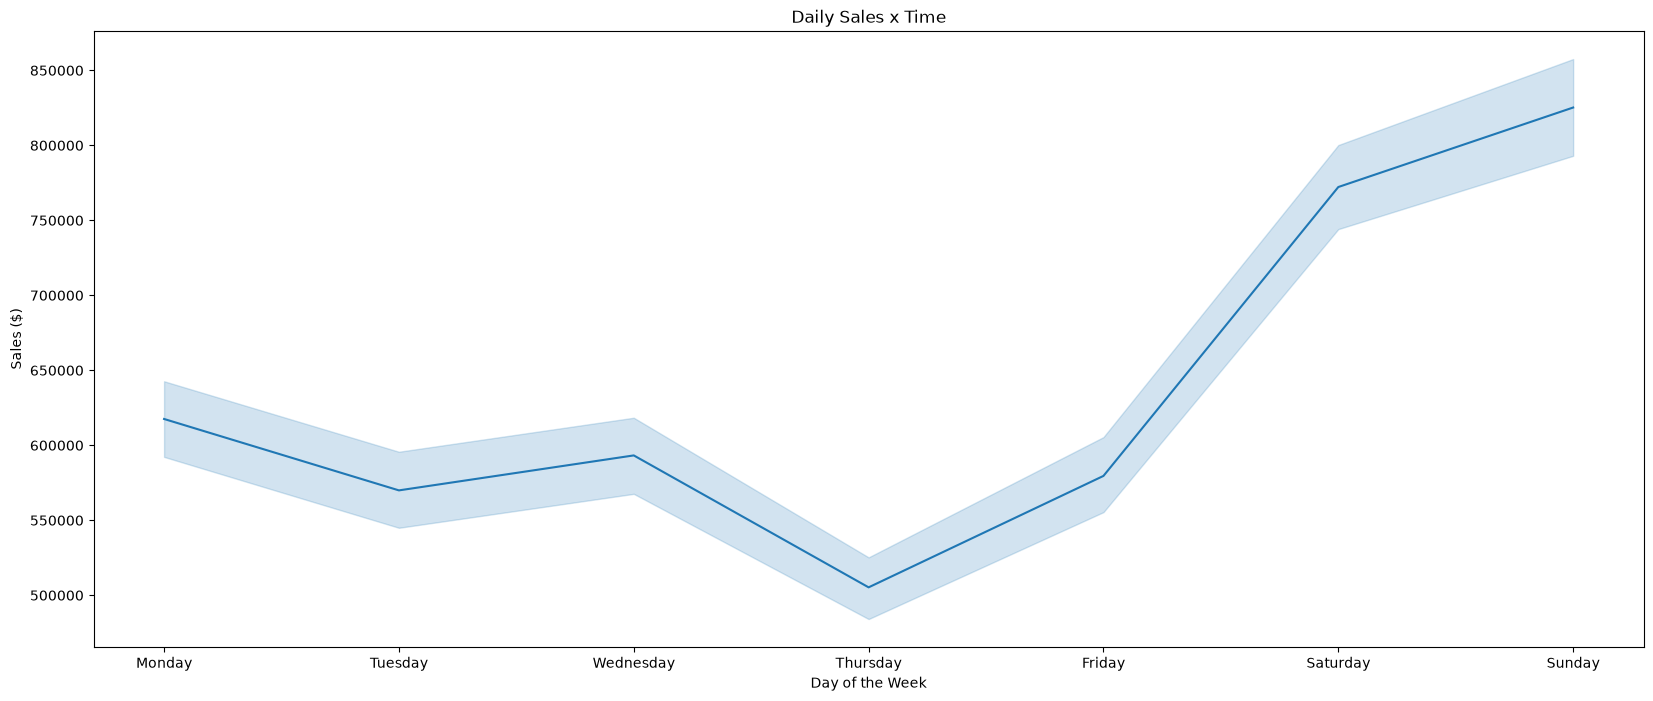

In [48]:
sales_by_date["week_day_name"] = pd.Categorical(
    sales_by_date["week_day_name"],
    categories=weekday_order,
    ordered=True
)

plt.figure(figsize=(20, 8))
sns.lineplot(
    data=sales_by_date,
    x="week_day_name",
    y="total_sales"
)
plt.title("Daily Sales x Time")
plt.xlabel("Day of the Week")
plt.ylabel("Sales ($)")

Average daily sales exhibit clear weekly seasonality. Sales are generally lower during weekdays, particularly on Thursdays, before increasing sharply on Saturdays and peaking on Sundays. Monday sales decline from the weekend peak but remain above most midweek levels. These findings suggest that day-of-week information could be a valuable predictor in subsequent forecasting models.

In [49]:
df[["sales", "onpromotion"]].corr()

,sales,onpromotion
sales,1.000000,0.427923
onpromotion,0.427923,1.000000


Sales and the number of items on promotion exhibit a moderate positive correlation (r = 0.428), suggesting that observations with more promoted items tend to have higher sales. However, differences in store size and product family may influence this relationship.

In [50]:
df[df["onpromotion"] == 0]["sales"].mean()

np.float64(158.24668139364272)

In [51]:
df[df["onpromotion"] > 0]["sales"].mean()

np.float64(1137.6937303133943)

In [52]:
1137/157

7.24203821656051

Observations with at least one promoted item exhibit approximately 7.2 times higher average sales than those without promotions (1,137.69 vs. 158.25). Combined with the moderate positive correlation (r = 0.428), this suggests promotional activity is an important candidate predictor for forecasting.